# M2-4C — Fine-tuning do BERTimbau com 4 cabeças de classificação (encoder compartilhado)

Variante arquitetural de `notebooks/bert/06.treinar_bertimbau.ipynb`: em vez de um único softmax de 9 classes (`O`, `B-CPF`, `I-CPF`, `B-RG`, `I-RG`, `B-NOME`, `I-NOME`, `B-ENDERECO`, `I-ENDERECO`) disputando espaço entre si, o mesmo encoder BERTimbau compartilhado alimenta **4 cabeças de classificação independentes** (uma por entidade — CPF, RG, NOME, ENDERECO), cada uma decidindo sozinha `O`/`B-<TIPO>`/`I-<TIPO>` em 3 classes.

**Motivação** (ver `anotacoes/anotacoes.txt` 2026-09-15): as 4 entidades são desbalanceadas (NOME ~10.900 exemplos, CPF ~4.700, RG/ENDERECO ~2.000-2.500) e competem no mesmo softmax — plausivelmente penalizando NOME (texto livre, mais difícil) frente a CPF/RG (padrão numérico mais regular e fácil). Separar em cabeças remove essa competição sem perder o encoder compartilhado (e o contexto sintático cruzado entre entidades vizinhas que ele carrega), nem multiplicar por 4 o custo de inferência de rodar 4 modelos inteiros separados.

**Reaproveita, sem duplicar:** todo o gabarito, extração OCR e alinhamento já produzidos pelo pipeline em `notebooks/bert/` (00-03, 07-09) — essas etapas não dependem da arquitetura do modelo. Este notebook só muda a partir da preparação do dataset em tags BIO.

**Protocolo mantido idêntico ao notebook de referência** (mesmos 10 cenários de hiperparâmetro, mesmo teto de épocas, mesma paciência de early stopping, mesmo `IOU_MINIMO_MATCH`, mesmo split 80/20 por documento) — para que a comparação entre as duas arquiteturas isole o efeito do desenho do modelo, não de um protocolo de treino diferente (ver `relatorio.tex`, metodologia).

**CIN fundida com CPF** (decisão 2026-09-09) — 4 entidades, não 5.

**Pré-requisitos:** `pip install transformers torch seqeval` (venv GERAL do projeto, `.venv`).

In [1]:
import json
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from seqeval.metrics import f1_score, precision_score, recall_score
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

print(f"CUDA disponível: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("Rodando em CPU — fine-tuning de transformer vai ser bem mais lento.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA disponível: True
GPU: NVIDIA GeForce RTX 5060 Ti


## Configuração

In [2]:
def encontrar_raiz_projeto(marcador: str = "requirements.txt") -> Path:
    p = Path.cwd()
    for _ in range(6):
        if (p / marcador).exists():
            return p
        p = p.parent
    raise RuntimeError(f"Não encontrei a raiz do projeto ({marcador}) subindo a partir de {Path.cwd()}")

RAIZ = encontrar_raiz_projeto()

import sys
sys.path.insert(0, str(RAIZ / "scripts"))
from pos_processamento_ner import comprimentos_subtokens, dividir_em_janelas_por_orcamento

MODELO_GABARITO = "gemini-2.5-flash"
INCLUIR_SINTETICOS = False  # ver notebooks/bert/06 -- False isola o efeito real do sintético

# Reaproveita os dados já produzidos pelo pipeline em notebooks/bert/ -- extração, alinhamento
# e gabarito não dependem da arquitetura do modelo.
PASTA_EXTRACAO = RAIZ / "data" / "documento_social" / "03.extracao_ocr_local"
PASTA_GABARITO_REAIS = RAIZ / "data" / "documento_social" / "04.gabarito_alinhado" / MODELO_GABARITO
PASTA_GABARITO_SINTETICOS = RAIZ / "data" / "documento_social" / "04.gabarito_alinhado" / "sintetico"
PASTA_MODELO_SAIDA = RAIZ / "models" / "bertimbau-4cabecas-pii-v1"
PASTA_MODELO_SAIDA.mkdir(parents=True, exist_ok=True)

CHECKPOINT_BASE = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT_BASE)  # carregado aqui (nao so na celula de
                                                              # tokenizacao) porque a divisao em
                                                              # janelas da preparacao do dataset ja
                                                              # precisa medir subtokens por palavra

TIPOS = ["CPF", "RG", "NOME", "ENDERECO"]  # CIN fundida com CPF (decisão 2026-09-09)
# uma cabeça de 3 classes por tipo, em vez de um único vetor de 9 classes
LABEL2ID_POR_TIPO = {tipo: {"O": 0, f"B-{tipo}": 1, f"I-{tipo}": 2} for tipo in TIPOS}
ID2LABEL_POR_TIPO = {tipo: {v: k for k, v in LABEL2ID_POR_TIPO[tipo].items()} for tipo in TIPOS}

LIMIAR_ALINHAMENTO_MINIMO_PCT = 80  # mesmo critério do notebook de referência (ver nota abaixo)
FRACAO_TREINO = 0.8
MAX_LENGTH = 512
SOBREPOSICAO_PALAVRAS_JANELA = 64   # paginas que passam do orcamento de subtokens viram varias
                                     # janelas (ver construir_exemplos_documento), mesmo valor
                                     # usado no notebook de referencia e na inferencia -- achado
                                     # 2026-09-15, ver anotacoes.txt
IOU_MINIMO_MATCH = 0.30

print(f"Raiz do projeto: {RAIZ}")
print(f"Extração:               {PASTA_EXTRACAO}")
print(f"Gabarito (reais):       {PASTA_GABARITO_REAIS}")
print(f"Gabarito (sintéticos):  {PASTA_GABARITO_SINTETICOS} (INCLUIR_SINTETICOS={INCLUIR_SINTETICOS})")
print(f"Modelo:                 {PASTA_MODELO_SAIDA}")
print(f"Cabeças ({len(TIPOS)}): {TIPOS} — 3 classes cada (O/B/I)")

Raiz do projeto: d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3
Extração:               d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\03.extracao_ocr_local
Gabarito (reais):       d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\04.gabarito_alinhado\gemini-2.5-flash
Gabarito (sintéticos):  d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\04.gabarito_alinhado\sintetico (INCLUIR_SINTETICOS=False)
Modelo:                 d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\models\bertimbau-4cabecas-pii-v1
Cabeças (4): ['CPF', 'RG', 'NOME', 'ENDERECO'] — 3 classes cada (O/B/I)


## Preparação do dataset: bbox → tags BIO por página, **uma lista de tags por cabeça**

Mesma lógica geométrica (bbox → índice de token) do notebook de referência. A diferença: em vez de uma única lista de tags por página, cada página gera um **dicionário de 4 listas de tags** (`tags_por_tipo`), uma por entidade — na lista de CPF, por exemplo, só posições de CPF recebem `B-CPF`/`I-CPF`; todo o resto (inclusive tokens que são NOME/RG/ENDERECO) é `O` para essa cabeça especificamente.

In [3]:
def bbox_contem_centro(caixa: list, bbox_token: list) -> bool:
    x0, y0, x1, y1 = caixa
    cx = (bbox_token[0] + bbox_token[2]) / 2
    cy = (bbox_token[1] + bbox_token[3]) / 2
    return (x0 - 1) <= cx <= (x1 + 1) and (y0 - 1) <= cy <= (y1 + 1)


def indices_tokens_da_entidade(tokens: list, entidade: dict) -> list:
    caixas = entidade.get("bbox") or []
    indices = []
    for i, tok in enumerate(tokens):
        for caixa in caixas:
            if bbox_contem_centro(caixa, tok["bbox"]):
                indices.append(i)
                break
    return sorted(set(indices))


def construir_exemplos_documento(extracao: dict, gabarito: dict) -> list:
    entidades_por_pagina = {}
    for e in gabarito["entities"]:
        if e.get("match_type") == "unmatched":
            continue
        entidades_por_pagina.setdefault(e["page"], []).append(e)

    exemplos = []
    for pagina_dados in extracao["pages"]:
        tokens_dict = pagina_dados["tokens"]
        if not tokens_dict:
            continue
        tokens = [t["text"] for t in tokens_dict]
        tokens_bbox = [t["bbox"] for t in tokens_dict]
        tags_por_tipo = {tipo: ["O"] * len(tokens) for tipo in TIPOS}
        for entidade in entidades_por_pagina.get(pagina_dados["page"], []):
            tipo = entidade["type"]
            if tipo not in TIPOS:
                continue
            indices = indices_tokens_da_entidade(tokens_dict, entidade)
            primeiro = True
            for i in indices:
                if tags_por_tipo[tipo][i] != "O":
                    continue  # já rotulado (raro); evita conflito
                tags_por_tipo[tipo][i] = f"{'B' if primeiro else 'I'}-{tipo}"
                primeiro = False

        # Divide a página em janelas deslizantes quando ultrapassa o orçamento de subtokens
        # do BERT -- mesma correção do notebook de referência (notebooks/bert/06), achado
        # 2026-09-15: sem isso, ~28% das entidades do gabarito real nunca geravam gradiente
        # (caíam depois do corte silencioso de MAX_LENGTH em tokenizar_e_alinhar). Cada janela
        # vira um exemplo de treino independente, com as 4 listas de tags recortadas junto.
        comprimentos = comprimentos_subtokens(tokenizer, tokens)
        orcamento = MAX_LENGTH - 2  # reserva para [CLS]/[SEP]
        if sum(comprimentos) <= orcamento:
            janelas = [(0, len(tokens))]
        else:
            janelas = dividir_em_janelas_por_orcamento(comprimentos, orcamento, SOBREPOSICAO_PALAVRAS_JANELA)

        for idx_janela, (ini, fim) in enumerate(janelas):
            exemplos.append({
                "document_id": extracao["document_id"],
                "page": pagina_dados["page"],
                "janela": idx_janela,  # 0 quando a página cabe inteira numa janela só
                "tokens": tokens[ini:fim],
                "tags_por_tipo": {tipo: tags[ini:fim] for tipo, tags in tags_por_tipo.items()},
                "tokens_bbox": tokens_bbox[ini:fim],
            })
    return exemplos


# Junta gabarito real + sintético (a não ser que INCLUIR_SINTETICOS=False), mesmo critério
# de filtro por % de alinhamento do notebook de referência (duplicata de span físico,
# notebooks/bert/03, não conta como falha -- ver anotacoes.txt 2026-09-14/15).
arquivos_gabarito = sorted(f for f in PASTA_GABARITO_REAIS.glob("*.json") if f.name != "_nao_alinhadas.json")
if INCLUIR_SINTETICOS:
    arquivos_gabarito += sorted(f for f in PASTA_GABARITO_SINTETICOS.glob("*.json") if f.name != "_nao_alinhadas.json")

if not arquivos_gabarito:
    raise SystemExit(f"Nenhum gabarito encontrado em {PASTA_GABARITO_REAIS} nem {PASTA_GABARITO_SINTETICOS}")

todos_exemplos = []
docs_descartados_alinhamento = []
for arq_gab in arquivos_gabarito:
    arq_ext = PASTA_EXTRACAO / arq_gab.name
    if not arq_ext.exists():
        print(f"[AVISO] Sem extração correspondente para {arq_gab.name}, pulando.")
        continue
    gabarito = json.loads(arq_gab.read_text(encoding="utf-8"))
    entidades = gabarito.get("entities", [])
    if not entidades:
        continue
    n_duplicatas = sum(
        1 for e in entidades
        if e.get("match_type") == "unmatched" and str(e.get("reason", "")).startswith("duplicata_span_fisico")
    )
    n_unmatched_genuino = sum(
        1 for e in entidades
        if e.get("match_type") == "unmatched" and not str(e.get("reason", "")).startswith("duplicata_span_fisico")
    )
    n_considerado = len(entidades) - n_duplicatas
    pct_alinhado = 100 * (n_considerado - n_unmatched_genuino) / n_considerado if n_considerado else 100.0
    if pct_alinhado < LIMIAR_ALINHAMENTO_MINIMO_PCT:
        docs_descartados_alinhamento.append((arq_gab.name, pct_alinhado, len(entidades)))
        continue
    extracao = json.loads(arq_ext.read_text(encoding="utf-8"))
    todos_exemplos.extend(construir_exemplos_documento(extracao, gabarito))

print(f"Documentos com >= {LIMIAR_ALINHAMENTO_MINIMO_PCT}% de alinhamento (usados no treino): "
      f"{len(arquivos_gabarito) - len(docs_descartados_alinhamento)}/{len(arquivos_gabarito)}")
n_paginas_unicas = len({(ex["document_id"], ex["page"]) for ex in todos_exemplos})
n_paginas_com_janela_extra = len({
    (ex["document_id"], ex["page"]) for ex in todos_exemplos if ex["janela"] > 0
})
print(f"\nTotal de exemplos (janelas): {len(todos_exemplos)} -- de {n_paginas_unicas} paginas unicas")
if n_paginas_com_janela_extra:
    print(f"Paginas que passaram do orcamento de {MAX_LENGTH} subtokens e viraram multiplas "
          f"janelas: {n_paginas_com_janela_extra} (achado 2026-09-15, ver anotacoes.txt)")
n_com_entidade = sum(1 for ex in todos_exemplos if any(t != "O" for tags in ex["tags_por_tipo"].values() for t in tags))
print(f"Exemplos com pelo menos 1 entidade: {n_com_entidade}")

Documentos com >= 80% de alinhamento (usados no treino): 921/999

Total de exemplos (janelas): 32600 -- de 7695 paginas unicas
Paginas que passaram do orcamento de 512 subtokens e viraram multiplas janelas: 5635 (achado 2026-09-15, ver anotacoes.txt)
Exemplos com pelo menos 1 entidade: 11314


## Split treino/validação por documento (mesmo critério do notebook de referência)

In [4]:
doc_ids = sorted({ex["document_id"] for ex in todos_exemplos})
rng = random.Random(SEED)
rng.shuffle(doc_ids)

n_treino = round(len(doc_ids) * FRACAO_TREINO)
n_treino = min(max(n_treino, 1), len(doc_ids) - 1)

docs_treino = set(doc_ids[:n_treino])
docs_validacao = set(doc_ids[n_treino:])

exemplos_treino = [ex for ex in todos_exemplos if ex["document_id"] in docs_treino]
exemplos_validacao = [ex for ex in todos_exemplos if ex["document_id"] in docs_validacao]

print(f"Split por documento: {FRACAO_TREINO:.0%} treino / {1 - FRACAO_TREINO:.0%} teste")
print(f"Documentos treino: {len(docs_treino)} | Documentos teste: {len(docs_validacao)}")
print(f"Páginas treino: {len(exemplos_treino)} | Páginas teste: {len(exemplos_validacao)}")

Split por documento: 80% treino / 20% teste
Documentos treino: 729 | Documentos teste: 182
Páginas treino: 26554 | Páginas teste: 6046


## Tokenização e alinhamento de labels em subpalavras — **um vetor de labels por cabeça**

Mesma receita padrão HuggingFace de alinhamento label→subpalavra do notebook de referência, repetida 4 vezes (uma por tipo), já que cada cabeça tem seu próprio espaço de labels (0=O, 1=B, 2=I).

In [5]:
def tokenizar_e_alinhar(tokens: list, tags_por_tipo: dict) -> dict:
    encoding = tokenizer(tokens, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    word_ids = encoding.word_ids()

    labels_por_tipo = {}
    for tipo in TIPOS:
        tags = tags_por_tipo[tipo]
        labels = []
        anterior = None
        for word_idx in word_ids:
            if word_idx is None:
                labels.append(-100)
            elif word_idx != anterior:
                labels.append(LABEL2ID_POR_TIPO[tipo][tags[word_idx]])
            else:
                tag = tags[word_idx]
                if tag.startswith("B-"):
                    tag = "I-" + tag[2:]
                labels.append(LABEL2ID_POR_TIPO[tipo][tag])
            anterior = word_idx
        labels_por_tipo[tipo] = labels

    encoding["labels_por_tipo"] = labels_por_tipo
    return {"input_ids": encoding["input_ids"], "attention_mask": encoding["attention_mask"],
            "labels_por_tipo": labels_por_tipo}


class DatasetNER4Cabecas(torch.utils.data.Dataset):
    def __init__(self, exemplos):
        self.exemplos = exemplos

    def __len__(self):
        return len(self.exemplos)

    def __getitem__(self, idx):
        ex = self.exemplos[idx]
        return tokenizar_e_alinhar(ex["tokens"], ex["tags_por_tipo"])


def colar_batch(batch: list) -> dict:
    """Collator próprio -- o `DataCollatorForTokenClassification` padrão só lida com UM
    campo `labels`; aqui há 4 (um por cabeça), então o padding de cada um precisa ser feito
    à mão, todos com -100 (ignorado na loss) nas posições de preenchimento."""
    max_len = max(len(item["input_ids"]) for item in batch)
    pad_id = tokenizer.pad_token_id

    input_ids, attention_mask = [], []
    labels_por_tipo = {tipo: [] for tipo in TIPOS}
    for item in batch:
        falta = max_len - len(item["input_ids"])
        input_ids.append(item["input_ids"] + [pad_id] * falta)
        attention_mask.append(item["attention_mask"] + [0] * falta)
        for tipo in TIPOS:
            labels_por_tipo[tipo].append(item["labels_por_tipo"][tipo] + [-100] * falta)

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
        "labels_por_tipo": {tipo: torch.tensor(v, dtype=torch.long) for tipo, v in labels_por_tipo.items()},
    }


dataset_treino = DatasetNER4Cabecas(exemplos_treino)
dataset_validacao = DatasetNER4Cabecas(exemplos_validacao)
print("Datasets prontos.")

Datasets prontos.


## Arquitetura: encoder BERTimbau compartilhado + 4 cabeças de classificação

`BERTimbau4Cabecas` roda o encoder **uma única vez** por página (mesmo custo de inferência do modelo de referência) e alimenta o `last_hidden_state` em 4 camadas lineares independentes (`hidden_size -> 3`), uma por tipo. A loss de treino é a soma das 4 entropias cruzadas (uma por cabeça, cada uma ignorando -100). Salvamento/carregamento são próprios (`save`/`load`), já que não é um `AutoModelForTokenClassification` padrão.

In [6]:
class BERTimbau4Cabecas(nn.Module):
    """Encoder compartilhado + uma cabeça de classificação (O/B/I, 3 classes) por entidade,
    em vez de um único softmax de 9 classes disputando espaço entre entidades desbalanceadas
    (ver anotacoes.txt 2026-09-15 e a introdução deste notebook)."""

    def __init__(self, checkpoint_base: str, tipos: list):
        super().__init__()
        self.tipos = list(tipos)
        self.encoder = AutoModel.from_pretrained(checkpoint_base)
        hidden = self.encoder.config.hidden_size
        p_dropout = getattr(self.encoder.config, "hidden_dropout_prob", 0.1)
        self.dropout = nn.Dropout(p_dropout)
        self.cabecas = nn.ModuleDict({tipo: nn.Linear(hidden, 3) for tipo in self.tipos})

    def forward(self, input_ids, attention_mask, labels_por_tipo: dict = None):
        saida_encoder = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        oculto = self.dropout(saida_encoder.last_hidden_state)
        logits_por_tipo = {tipo: self.cabecas[tipo](oculto) for tipo in self.tipos}

        loss = None
        if labels_por_tipo is not None:
            perda_fn = nn.CrossEntropyLoss(ignore_index=-100)
            loss = 0.0
            for tipo in self.tipos:
                loss = loss + perda_fn(logits_por_tipo[tipo].view(-1, 3), labels_por_tipo[tipo].view(-1))
        return {"loss": loss, "logits_por_tipo": logits_por_tipo}

    def save(self, pasta):
        pasta = Path(pasta)
        pasta.mkdir(parents=True, exist_ok=True)
        self.encoder.save_pretrained(pasta / "encoder")
        torch.save({tipo: self.cabecas[tipo].state_dict() for tipo in self.tipos}, pasta / "cabecas.pt")
        (pasta / "config_4cabecas.json").write_text(
            json.dumps({"tipos": self.tipos}, ensure_ascii=False, indent=2), encoding="utf-8"
        )

    @classmethod
    def load(cls, pasta, device="cpu"):
        pasta = Path(pasta)
        config = json.loads((pasta / "config_4cabecas.json").read_text(encoding="utf-8"))
        modelo = cls(str(pasta / "encoder"), config["tipos"])
        cabecas_state = torch.load(pasta / "cabecas.pt", map_location=device)
        for tipo in config["tipos"]:
            modelo.cabecas[tipo].load_state_dict(cabecas_state[tipo])
        return modelo.to(device)


print("Classe BERTimbau4Cabecas definida.")

Classe BERTimbau4Cabecas definida.


## Avaliação — reconstrói UM rótulo por token a partir das 4 cabeças

Para comparar com o mesmo `seqeval` usado no notebook de referência (protocolo idêntico), as previsões das 4 cabeças são reconciliadas token a token num único rótulo: se mais de uma cabeça prevê não-`O` na mesma posição (conflito raro), vence a de maior confiança (softmax). O gold nunca tem conflito real (entidades não se sobrepõem no gabarito), mas a reconstrução segue a mesma regra por simetria.

In [7]:
@torch.no_grad()
def avaliar_epoca(modelo, loader) -> dict:
    modelo.eval()
    todas_gold, todas_pred = [], []
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_por_tipo = batch["labels_por_tipo"]

        saida = modelo(input_ids=input_ids, attention_mask=attention_mask)
        logits_por_tipo = saida["logits_por_tipo"]
        preds_por_tipo = {tipo: logits_por_tipo[tipo].argmax(dim=-1).cpu() for tipo in TIPOS}
        scores_por_tipo = {tipo: logits_por_tipo[tipo].softmax(dim=-1).max(dim=-1).values.cpu() for tipo in TIPOS}

        batch_tam, seq_len = input_ids.shape
        for i in range(batch_tam):
            gold_seq, pred_seq = [], []
            for j in range(seq_len):
                if all(labels_por_tipo[tipo][i, j].item() == -100 for tipo in TIPOS):
                    continue  # padding / subpalavra / token especial

                label_gold = "O"
                for tipo in TIPOS:
                    lid = labels_por_tipo[tipo][i, j].item()
                    if lid not in (-100, 0):
                        label_gold = ID2LABEL_POR_TIPO[tipo][lid]
                        break
                gold_seq.append(label_gold)

                candidatos = []
                for tipo in TIPOS:
                    pid = preds_por_tipo[tipo][i, j].item()
                    if pid != 0:
                        candidatos.append((scores_por_tipo[tipo][i, j].item(), ID2LABEL_POR_TIPO[tipo][pid]))
                pred_seq.append(max(candidatos)[1] if candidatos else "O")

            todas_gold.append(gold_seq)
            todas_pred.append(pred_seq)

    return {
        "precision": precision_score(todas_gold, todas_pred),
        "recall": recall_score(todas_gold, todas_pred),
        "f1": f1_score(todas_gold, todas_pred),
    }


print("Função de avaliação definida.")

Função de avaliação definida.


## Busca de hiperparâmetros (10 cenários, todos com early stopping)

Mesmos 10 cenários do notebook de referência (`notebooks/bert/06`), mesmo teto de épocas e paciência — loop de treino manual em PyTorch puro (o `Trainer` do HuggingFace pressupõe um único vetor de `labels`, não 4; ver `colar_batch`/`avaliar_epoca` acima).

In [8]:
MAX_EPOCAS_TETO = 30
PACIENCIA_EARLY_STOPPING = 3

CENARIOS = [
    {"nome": "c01_baseline",       "learning_rate": 3e-5, "batch_size": 4,  "weight_decay": 0.01, "warmup_ratio": 0.0},
    {"nome": "c02_lr_baixo",       "learning_rate": 2e-5, "batch_size": 4,  "weight_decay": 0.01, "warmup_ratio": 0.0},
    {"nome": "c03_lr_alto",        "learning_rate": 5e-5, "batch_size": 4,  "weight_decay": 0.01, "warmup_ratio": 0.0},
    {"nome": "c04_batch8",         "learning_rate": 3e-5, "batch_size": 8,  "weight_decay": 0.01, "warmup_ratio": 0.0},
    {"nome": "c05_batch16",        "learning_rate": 3e-5, "batch_size": 16, "weight_decay": 0.01, "warmup_ratio": 0.0},
    {"nome": "c06_sem_weight_decay", "learning_rate": 3e-5, "batch_size": 4, "weight_decay": 0.0, "warmup_ratio": 0.0},
    {"nome": "c07_weight_decay_alto", "learning_rate": 3e-5, "batch_size": 4, "weight_decay": 0.1, "warmup_ratio": 0.0},
    {"nome": "c08_warmup",         "learning_rate": 3e-5, "batch_size": 4,  "weight_decay": 0.01, "warmup_ratio": 0.1},
    {"nome": "c09_lrbaixo_batch8_warmup", "learning_rate": 1e-5, "batch_size": 8, "weight_decay": 0.01, "warmup_ratio": 0.1},
    {"nome": "c10_lralto_batch16_wdalto_warmup", "learning_rate": 5e-5, "batch_size": 16, "weight_decay": 0.1, "warmup_ratio": 0.1},
]

_sufixo_experimento = "-com-sinteticos" if INCLUIR_SINTETICOS else "-sem-sinteticos"
PASTA_CENARIOS = PASTA_MODELO_SAIDA.parent / f"bertimbau-4cabecas-pii-v1-cenarios{_sufixo_experimento}"
PASTA_CENARIOS.mkdir(parents=True, exist_ok=True)
print(f"Cenários serão salvos em: {PASTA_CENARIOS}")


def treinar_cenario(cenario: dict) -> dict:
    modelo = BERTimbau4Cabecas(CHECKPOINT_BASE, TIPOS).to(device)
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=cenario["learning_rate"], weight_decay=cenario["weight_decay"])

    loader_treino = torch.utils.data.DataLoader(
        dataset_treino, batch_size=cenario["batch_size"], shuffle=True, collate_fn=colar_batch
    )
    loader_val = torch.utils.data.DataLoader(
        dataset_validacao, batch_size=cenario["batch_size"], shuffle=False, collate_fn=colar_batch
    )

    passos_por_epoca = len(loader_treino)
    passos_totais = passos_por_epoca * MAX_EPOCAS_TETO
    warmup_ratio = cenario["warmup_ratio"]
    passos_warmup = int(passos_totais * warmup_ratio) if warmup_ratio < 1 else int(warmup_ratio)
    agendador = get_linear_schedule_with_warmup(otimizador, num_warmup_steps=passos_warmup, num_training_steps=passos_totais)

    melhor_f1 = -1.0
    melhor_estado = None
    melhor_metricas = None
    epocas_efetivas = 0
    paciencia_restante = PACIENCIA_EARLY_STOPPING

    inicio_total = time.time()
    for epoca in range(1, MAX_EPOCAS_TETO + 1):
        modelo.train()
        inicio_epoca = time.time()
        perda_acumulada = 0.0
        for passo, batch in enumerate(loader_treino, start=1):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_por_tipo = {t: v.to(device) for t, v in batch["labels_por_tipo"].items()}

            otimizador.zero_grad()
            saida = modelo(input_ids=input_ids, attention_mask=attention_mask, labels_por_tipo=labels_por_tipo)
            saida["loss"].backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            otimizador.step()
            agendador.step()
            perda_acumulada += saida["loss"].item()
            if passo % 50 == 0:
                print(f"  [passo {passo}/{passos_por_epoca}] loss={saida['loss'].item():.4f}")

        duracao_epoca = time.time() - inicio_epoca
        loss_medio = perda_acumulada / passos_por_epoca
        print(f"=== Época {epoca}/{MAX_EPOCAS_TETO} concluída em {duracao_epoca:.1f}s (loss médio {loss_medio:.4f}) ===")

        metricas = avaliar_epoca(modelo, loader_val)
        print(f"  >> avaliação: precision={metricas['precision']:.3f} recall={metricas['recall']:.3f} f1={metricas['f1']:.3f}")

        if metricas["f1"] > melhor_f1:
            melhor_f1 = metricas["f1"]
            melhor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
            melhor_metricas = metricas
            epocas_efetivas = epoca
            paciencia_restante = PACIENCIA_EARLY_STOPPING
        else:
            paciencia_restante -= 1
            if paciencia_restante <= 0:
                print(f"  Early stopping (sem melhora por {PACIENCIA_EARLY_STOPPING} avaliações).")
                break

    duracao_total = time.time() - inicio_total
    modelo.load_state_dict(melhor_estado)
    return {
        "modelo": modelo,
        "epocas_efetivas": epocas_efetivas,
        "duracao_treino_s": round(duracao_total, 1),
        "eval_f1": melhor_metricas["f1"],
        "eval_precision": melhor_metricas["precision"],
        "eval_recall": melhor_metricas["recall"],
    }


resultados_cenarios = []
for cenario in CENARIOS:
    nome = cenario["nome"]
    pasta_cenario = PASTA_CENARIOS / nome
    pasta_cenario.mkdir(parents=True, exist_ok=True)
    print(f"\n{'=' * 70}\nCenário: {nome} -> {cenario}\n{'=' * 70}")

    resultado_treino = treinar_cenario(cenario)
    resultado_treino["modelo"].save(pasta_cenario)
    tokenizer.save_pretrained(pasta_cenario / "encoder")
    (pasta_cenario / "hiperparametros.json").write_text(json.dumps(cenario, ensure_ascii=False, indent=2), encoding="utf-8")

    resultado = {
        "nome": nome,
        **{k: v for k, v in cenario.items() if k != "nome"},
        "epocas_efetivas": resultado_treino["epocas_efetivas"],
        "duracao_treino_s": resultado_treino["duracao_treino_s"],
        "eval_f1": resultado_treino["eval_f1"],
        "eval_precision": resultado_treino["eval_precision"],
        "eval_recall": resultado_treino["eval_recall"],
        "pasta_modelo": str(pasta_cenario),
    }
    resultados_cenarios.append(resultado)
    print(f"\n>> {nome} concluído em {resultado_treino['duracao_treino_s']:.1f}s "
          f"({resultado_treino['epocas_efetivas']} épocas efetivas) -> F1={resultado_treino['eval_f1']:.4f} "
          f"precision={resultado_treino['eval_precision']:.4f} recall={resultado_treino['eval_recall']:.4f}")

    del resultado_treino
    torch.cuda.empty_cache()

print(f"\nTodos os {len(CENARIOS)} cenários concluídos.")

Cenários serão salvos em: d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\models\bertimbau-4cabecas-pii-v1-cenarios-sem-sinteticos

Cenário: c01_baseline -> {'nome': 'c01_baseline', 'learning_rate': 3e-05, 'batch_size': 4, 'weight_decay': 0.01, 'warmup_ratio': 0.0}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 24880.51it/s]
[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [passo 50/6639] loss=0.0585
  [passo 100/6639] loss=0.0758
  [passo 150/6639] loss=0.0268
  [passo 200/6639] loss=0.2435
  [passo 250/6639] loss=0.1179
  [passo 300/6639] loss=0.0040
  [passo 350/6639] loss=0.2617
  [passo 400/6639] loss=0.0849
  [passo 450/6639] loss=0.0361
  [passo 500/6639] loss=0.0023
  [passo 550/6639] loss=0.0780
  [passo 600/6639] loss=0.0248
  [passo 650/6639] loss=0.0692
  [passo 700/6639] loss=0.0016
  [passo 750/6639] loss=0.0015
  [passo 800/6639] loss=0.0189
  [passo 850/6639] loss=0.0471
  [passo 900/6639] loss=0.0408
  [passo 950/6639] loss=0.0087
  [passo 1000/6639] loss=0.0050
  [passo 1050/6639] loss=0.0047
  [passo 1100/6639] loss=0.0761
  [passo 1150/6639] loss=0.0621
  [passo 1200/6639] loss=0.0165
  [passo 1250/6639] loss=0.1182
  [passo 1300/6639] loss=0.0150
  [passo 1350/6639] loss=0.0046
  [passo 1400/6639] loss=0.0521
  [passo 1450/6639] loss=0.0648
  [passo 1500/6639] loss=0.1002
  [passo 1550/6639] loss=0.0358
  [passo 1600/6639] loss=0.0

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.49s/it]



>> c01_baseline concluído em 8466.0s (4 épocas efetivas) -> F1=0.6732 precision=0.6288 recall=0.7244

Cenário: c02_lr_baixo -> {'nome': 'c02_lr_baixo', 'learning_rate': 2e-05, 'batch_size': 4, 'weight_decay': 0.01, 'warmup_ratio': 0.0}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 33178.30it/s]
[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (31 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 28187.72it/s]
[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [passo 50/1660] loss=3.9336
  [passo 100/1660] loss=2.6602
  [passo 150/1660] loss=1.0060
  [passo 200/1660] loss=0.2778
  [passo 250/1660] loss=0.2546
  [passo 300/1660] loss=0.1085
  [passo 350/1660] loss=0.0718
  [passo 400/1660] loss=0.1548
  [passo 450/1660] loss=0.1925
  [passo 500/1660] loss=0.0602
  [passo 550/1660] loss=0.0785
  [passo 600/1660] loss=0.0723
  [passo 650/1660] loss=0.0470
  [passo 700/1660] loss=0.0784
  [passo 750/1660] loss=0.0348
  [passo 800/1660] loss=0.0385
  [passo 850/1660] loss=0.0415
  [passo 900/1660] loss=0.0250
  [passo 950/1660] loss=0.0885
  [passo 1000/1660] loss=0.0369
  [passo 1050/1660] loss=0.0698
  [passo 1100/1660] loss=0.0139
  [passo 1150/1660] loss=0.0577
  [passo 1200/1660] loss=0.0443
  [passo 1250/1660] loss=0.0217
  [passo 1300/1660] loss=0.0162
  [passo 1350/1660] loss=0.0619
  [passo 1400/1660] loss=0.0294
  [passo 1450/1660] loss=0.0370
  [passo 1500/1660] loss=0.0227
  [passo 1550/1660] loss=0.0332
  [passo 1600/1660] loss=0.0

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.32s/it]


>> c10_lralto_batch16_wdalto_warmup concluído em 10423.9s (7 épocas efetivas) -> F1=0.7036 precision=0.6766 recall=0.7330

Todos os 10 cenários concluídos.


## Comparação entre os cenários

In [9]:
resultados_ordenados = sorted(resultados_cenarios, key=lambda r: r["eval_f1"], reverse=True)

arq_comparacao = PASTA_CENARIOS / "_comparacao_cenarios.json"
arq_comparacao.write_text(json.dumps(resultados_ordenados, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Comparação salva em {arq_comparacao}")

cabecalho = (
    f"{'Cenário':<32}{'LR':<9}{'Batch':<7}{'WD':<6}{'Warmup':<8}"
    f"{'Épocas':<8}{'F1':<8}{'Precision':<11}{'Recall':<9}{'Tempo(s)':<9}"
)
print(f"\n{cabecalho}")
print("-" * len(cabecalho))
for r in resultados_ordenados:
    print(
        f"{r['nome']:<32}{r['learning_rate']:<9}{r['batch_size']:<7}{r['weight_decay']:<6}"
        f"{r['warmup_ratio']:<8}{r['epocas_efetivas']:<8}{r['eval_f1']:<8.4f}"
        f"{r['eval_precision']:<11.4f}{r['eval_recall']:<9.4f}{r['duracao_treino_s']:<9.1f}"
    )

melhor_cenario = resultados_ordenados[0]
print(f"\nMelhor cenário: {melhor_cenario['nome']} (F1={melhor_cenario['eval_f1']:.4f}) -> {melhor_cenario['pasta_modelo']}")

Comparação salva em d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\models\bertimbau-4cabecas-pii-v1-cenarios-sem-sinteticos\_comparacao_cenarios.json

Cenário                         LR       Batch  WD    Warmup  Épocas  F1      Precision  Recall   Tempo(s) 
-----------------------------------------------------------------------------------------------------------
c02_lr_baixo                    2e-05    4      0.01  0.0     3       0.7042  0.6351     0.7900   7529.5   
c10_lralto_batch16_wdalto_warmup5e-05    16     0.1   0.1     7       0.7036  0.6766     0.7330   10423.9  
c06_sem_weight_decay            3e-05    4      0.0   0.0     8       0.6969  0.6971     0.6966   12987.1  
c08_warmup                      3e-05    4      0.01  0.1     8       0.6953  0.6846     0.7064   13319.8  
c07_weight_decay_alto           3e-05    4      0.1   0.0     3       0.6950  0.6471     0.7505   7144.9   
c05_batch16                     3e-05    16     0.01  0.0     4       0.6852  0.6537    

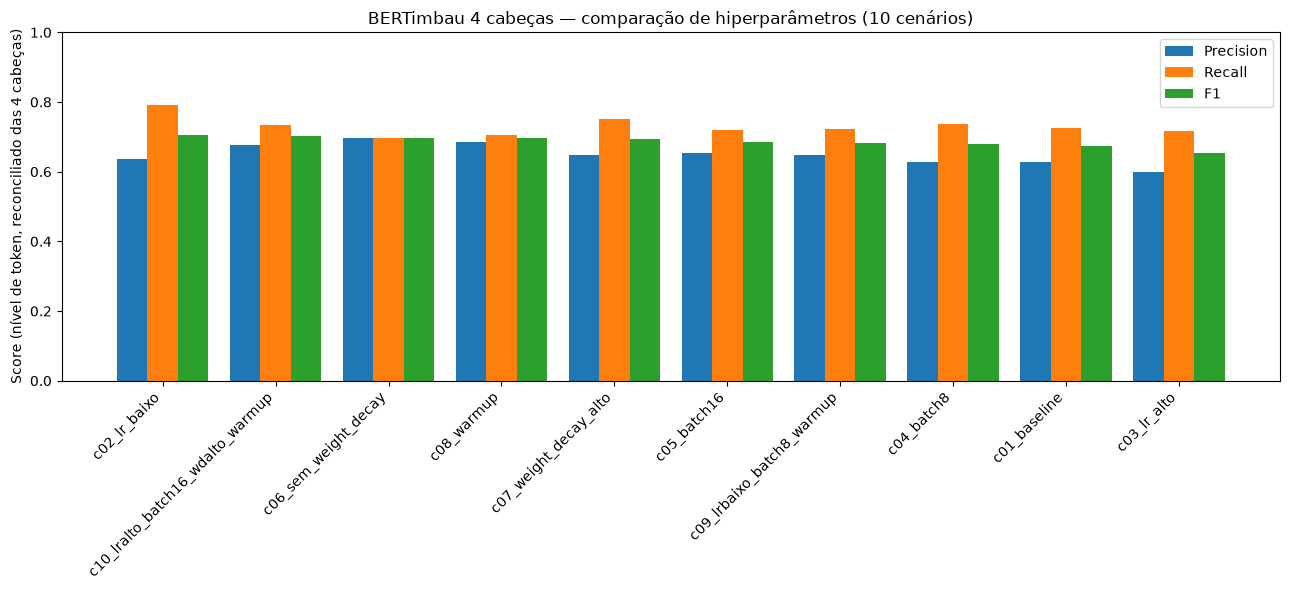

In [10]:
import matplotlib.pyplot as plt

nomes = [r["nome"] for r in resultados_ordenados]
f1s = [r["eval_f1"] for r in resultados_ordenados]
precisions = [r["eval_precision"] for r in resultados_ordenados]
recalls = [r["eval_recall"] for r in resultados_ordenados]

x = list(range(len(nomes)))
largura = 0.27

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar([i - largura for i in x], precisions, width=largura, label="Precision")
ax.bar(x, recalls, width=largura, label="Recall")
ax.bar([i + largura for i in x], f1s, width=largura, label="F1")

ax.set_xticks(x)
ax.set_xticklabels(nomes, rotation=45, ha="right")
ax.set_ylabel("Score (nível de token, reconciliado das 4 cabeças)")
ax.set_title("BERTimbau 4 cabeças — comparação de hiperparâmetros (10 cenários)")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## Avaliação por bbox do melhor cenário (comparável aos notebooks 04/05/bert-06)

Mesma lógica de decodificação BIO→bbox do notebook de referência, mas decodificando cada cabeça separadamente e juntando as 4 listas de entidades no final — cada cabeça só decide sobre seu próprio tipo, não há ambiguidade de "qual tipo escolher" na decodificação (diferente da reconciliação usada em `avaliar_epoca`, que existe só para comparar com `seqeval`).

In [11]:
def agrupar_bboxes_por_linha(tokens_bbox: list, indices: list) -> list:
    if not indices:
        return []
    grupos = []
    grupo_atual = [tokens_bbox[indices[0]]]
    y_ref = tokens_bbox[indices[0]][1]
    for i in indices[1:]:
        bbox = tokens_bbox[i]
        altura_ref = grupo_atual[-1][3] - grupo_atual[-1][1]
        if abs(bbox[1] - y_ref) > max(altura_ref * 0.6, 3):
            grupos.append(grupo_atual)
            grupo_atual = [bbox]
            y_ref = bbox[1]
        else:
            grupo_atual.append(bbox)
    grupos.append(grupo_atual)
    return [[min(b[0] for b in g), min(b[1] for b in g), max(b[2] for b in g), max(b[3] for b in g)] for g in grupos]


def bbox_externo(lista_bboxes: list):
    if not lista_bboxes:
        return None
    return [min(b[0] for b in lista_bboxes), min(b[1] for b in lista_bboxes),
            max(b[2] for b in lista_bboxes), max(b[3] for b in lista_bboxes)]


def iou(a, b) -> float:
    if a is None or b is None:
        return 0.0
    xi0, yi0 = max(a[0], b[0]), max(a[1], b[1])
    xi1, yi1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, xi1 - xi0) * max(0, yi1 - yi0)
    if inter == 0:
        return 0.0
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    uniao = area_a + area_b - inter
    return inter / uniao if uniao > 0 else 0.0


@torch.no_grad()
def prever_pagina_4cabecas(modelo, tokens: list, tokens_bbox: list) -> list:
    encoding = tokenizer(tokens, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
    encoding = {k: v.to(device) for k, v in encoding.items()}
    saida = modelo(**encoding)
    word_ids = tokenizer(tokens, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH).word_ids()

    entidades = []
    for tipo in TIPOS:
        pred_ids = saida["logits_por_tipo"][tipo][0].argmax(dim=-1).tolist()
        tags_por_palavra = ["O"] * len(tokens)
        visto = set()
        for pid, word_idx in zip(pred_ids, word_ids):
            if word_idx is None or word_idx in visto:
                continue
            visto.add(word_idx)
            tags_por_palavra[word_idx] = ID2LABEL_POR_TIPO[tipo][pid]

        i, n = 0, len(tags_por_palavra)
        while i < n:
            if tags_por_palavra[i] == "O":
                i += 1
                continue
            indices = [i]
            j = i + 1
            while j < n and tags_por_palavra[j] == f"I-{tipo}":
                indices.append(j)
                j += 1
            entidades.append({
                "type": tipo,
                "bbox": agrupar_bboxes_por_linha(tokens_bbox, indices),
                "indices": indices,
                "text": " ".join(tokens[k] for k in indices),
            })
            i = j
    return entidades


model = BERTimbau4Cabecas.load(melhor_cenario["pasta_modelo"], device=device)
model.eval()
print(f"Modelo carregado para avaliação por bbox: {melhor_cenario['nome']} ({melhor_cenario['pasta_modelo']})")

gabarito_por_doc_pagina = {}
for arq_gab in arquivos_gabarito:
    gabarito = json.loads(arq_gab.read_text(encoding="utf-8"))
    for e in gabarito["entities"]:
        if e.get("match_type") == "unmatched":
            continue
        gabarito_por_doc_pagina.setdefault((gabarito["document_id"], e["page"]), []).append(e)


def avaliar_paginas(exemplos: list) -> dict:
    contadores = {t: {"tp": 0, "fp": 0, "fn": 0} for t in TIPOS}
    for ex in exemplos:
        previstas = prever_pagina_4cabecas(model, ex["tokens"], ex["tokens_bbox"])
        gold = gabarito_por_doc_pagina.get((ex["document_id"], ex["page"]), [])

        previstas_por_tipo = {}
        for p in previstas:
            previstas_por_tipo.setdefault(p["type"], []).append(p)

        usadas = set()
        for g in gold:
            tipo = g["type"]
            candidatos = previstas_por_tipo.get(tipo, [])
            bbox_gold = bbox_externo(g.get("bbox") or [])
            melhor_iou, melhor_idx = 0.0, None
            for i, p in enumerate(candidatos):
                if id(p) in usadas:
                    continue
                score = iou(bbox_gold, bbox_externo(p["bbox"]))
                if score > melhor_iou:
                    melhor_iou, melhor_idx = score, i
            if melhor_idx is not None and melhor_iou >= IOU_MINIMO_MATCH:
                usadas.add(id(candidatos[melhor_idx]))
                contadores[tipo]["tp"] += 1
            else:
                contadores[tipo]["fn"] += 1

        for tipo, candidatos in previstas_por_tipo.items():
            for p in candidatos:
                if id(p) not in usadas:
                    contadores.setdefault(tipo, {"tp": 0, "fp": 0, "fn": 0})
                    contadores[tipo]["fp"] += 1
    return contadores


def imprimir_tabela(titulo: str, contadores: dict, n_docs: int, n_paginas: int):
    print(f"\n=== {titulo} ({n_docs} documento(s), {n_paginas} página(s)) ===")
    print(f"{'Tipo':<10}{'TP':<6}{'FP':<6}{'FN':<6}{'Precision':<12}{'Recall':<10}{'F1':<8}")
    print("-" * 62)
    tp_g = fp_g = fn_g = 0
    for tipo in TIPOS:
        c = contadores[tipo]
        tp, fp, fn = c["tp"], c["fp"], c["fn"]
        tp_g += tp; fp_g += fp; fn_g += fn
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
        print(f"{tipo:<10}{tp:<6}{fp:<6}{fn:<6}{precision:<12.3f}{recall:<10.3f}{f1:<8.3f}")
    precision_g = tp_g / (tp_g + fp_g) if (tp_g + fp_g) else 0.0
    recall_g = tp_g / (tp_g + fn_g) if (tp_g + fn_g) else 0.0
    f1_g = 2 * precision_g * recall_g / (precision_g + recall_g) if (precision_g + recall_g) else 0.0
    print("-" * 62)
    print(f"{'GERAL':<10}{tp_g:<6}{fp_g:<6}{fn_g:<6}{precision_g:<12.3f}{recall_g:<10.3f}{f1_g:<8.3f}")


contadores_geral = avaliar_paginas(exemplos_validacao)
imprimir_tabela("GERAL (reais + sintéticos)", contadores_geral, len(docs_validacao), len(exemplos_validacao))

exemplos_validacao_reais = [ex for ex in exemplos_validacao if not ex["document_id"].startswith("sintetico_")]
exemplos_validacao_sinteticos = [ex for ex in exemplos_validacao if ex["document_id"].startswith("sintetico_")]
docs_validacao_reais = {d for d in docs_validacao if not d.startswith("sintetico_")}
docs_validacao_sinteticos = {d for d in docs_validacao if d.startswith("sintetico_")}

if exemplos_validacao_reais:
    contadores_reais = avaliar_paginas(exemplos_validacao_reais)
    imprimir_tabela("SÓ DOCUMENTOS REAIS de teste", contadores_reais, len(docs_validacao_reais), len(exemplos_validacao_reais))
if exemplos_validacao_sinteticos:
    contadores_sinteticos = avaliar_paginas(exemplos_validacao_sinteticos)
    imprimir_tabela("SÓ DOCUMENTOS SINTÉTICOS de teste", contadores_sinteticos, len(docs_validacao_sinteticos), len(exemplos_validacao_sinteticos))

print(
    "\nCompare com notebooks/bert/06 (mesmo protocolo, mesma base de dados) para isolar o "
    "efeito da arquitetura de 4 cabeças frente ao softmax único de 9 classes."
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6851.64it/s]


Modelo carregado para avaliação por bbox: c02_lr_baixo (d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\models\bertimbau-4cabecas-pii-v1-cenarios-sem-sinteticos\c02_lr_baixo)


TypeError: BERTimbau4Cabecas.forward() got an unexpected keyword argument 'token_type_ids'